<a href="https://colab.research.google.com/github/it21023996/machine-learning/blob/main/CNN_cifar10_Tensorflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import datasets,layers,models

In [54]:
(x_train,y_train),(x_test,y_test)=datasets.cifar10.load_data()

In [55]:
x_train.shape,y_train.shape,x_test.shape,y_test.shape

((50000, 32, 32, 3), (50000, 1), (10000, 32, 32, 3), (10000, 1))

In [56]:
classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

In [57]:
classes[2]

'bird'

In [58]:
def plot_sample(x,y,number):
  plt.figure(figsize=(15,2))
  plt.imshow(x[number])
  i = y[number]
  plt.xlabel(classes[int(i)])

/tmp/ipython-input-4269355419.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.xlabel(classes[int(i)])


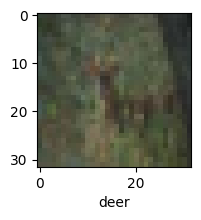

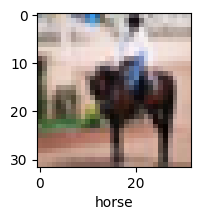

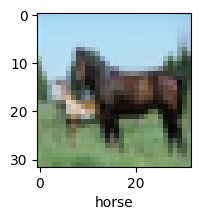

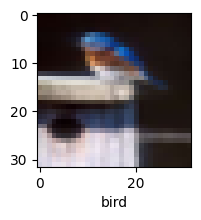

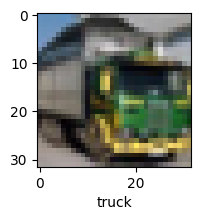

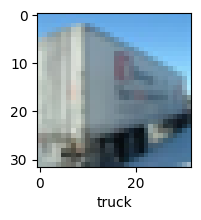

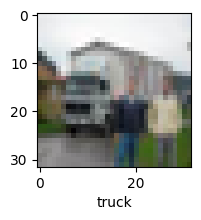

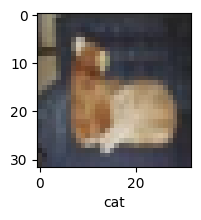

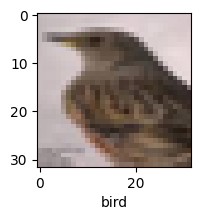

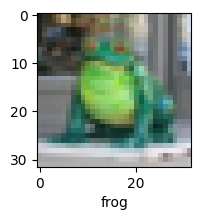

In [59]:
for i in range(10,20):
  plot_sample(x_train,y_train,i)

In [60]:
x_train = x_train/255.0
x_test = x_test/255.0

In [61]:
cnn = models.Sequential([
     layers.Conv2D(filters=32,kernel_size=(3,3),activation='relu',input_shape= (32,32,3)),
     layers.MaxPool2D((2,2)),

     layers.Conv2D(filters=64,kernel_size=(3,3),activation = 'relu'),
     layers.MaxPool2D((2,2)),

     layers.Flatten(),
     layers.Dense(64,activation = 'relu'),
     layers.Dense(10,activation = 'softmax')
])

In [62]:
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics= ['accuracy'])

In [63]:
print(y_train[:10])

[[6]
 [9]
 [9]
 [4]
 [1]
 [1]
 [2]
 [7]
 [8]
 [3]]


In [64]:
cnn.fit(x_train,y_train,epochs = 10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 59s 36ms/step - accuracy: 0.3636 - loss: 1.7421
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 35ms/step - accuracy: 0.5847 - loss: 1.1863
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 58s 37ms/step - accuracy: 0.6494 - loss: 1.0139
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 55s 35ms/step - accuracy: 0.6889 - loss: 0.9005
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 36ms/step - accuracy: 0.7121 - loss: 0.8316
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.7282 - loss: 0.7762
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 36ms/step - accuracy: 0.7445 - loss: 0.7243
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 36ms/step - accuracy: 0.7655 - loss: 0.6721
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 56s 36ms/step - accuracy: 0.7769 - loss: 0.6371
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 55s 35ms/step - accuracy: 0.7891 - loss: 0.5998


In [65]:
cnn.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6952 - loss: 0.9291


[0.9403215050697327, 0.6922000050544739]

In [66]:
y_pred = cnn.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


In [67]:
y_pred[:5]

array([[6.54055446e-04, 3.65412488e-05, 9.83222015e-03, 8.88491631e-01,
        9.59553945e-05, 9.31426287e-02, 3.66944657e-03, 1.64423545e-05,
        3.99708562e-03, 6.39507416e-05],
       [8.42854287e-03, 4.65878472e-02, 3.10413270e-06, 7.23277344e-06,
        7.71257362e-07, 4.45365600e-07, 3.49940237e-08, 3.93048580e-08,
        9.44447339e-01, 5.24773262e-04],
       [2.77216434e-01, 4.30272222e-02, 9.40962322e-03, 2.26992350e-02,
        7.21069425e-03, 6.43317169e-03, 4.63902921e-04, 1.29479589e-02,
        5.19195497e-01, 1.01396248e-01],
       [6.88711643e-01, 3.15672456e-04, 2.64927838e-02, 3.55210761e-03,
        7.06593134e-03, 1.45463579e-04, 1.69844461e-05, 1.46885694e-03,
        2.72159189e-01, 7.12980691e-05],
       [2.55664844e-07, 1.73141359e-07, 3.63691314e-03, 1.82106812e-02,
        1.53312208e-02, 2.47458369e-03, 9.60327864e-01, 1.03843746e-07,
        1.82729018e-05, 3.65305404e-08]], dtype=float32)

In [73]:
y_pred.shape

(10000, 10)

In [81]:
y_class = np.array([np.argmax(x) for x in y_pred[:10000]])

In [82]:
y_class.shape

(10000,)

In [87]:
y_class[77]

np.int64(3)

In [88]:
def plot(x,y,i):
  plt.figure(figsize = (15,2))
  plt.imshow(x[i])
  plt.xlabel(classes[int(y[i])])

/tmp/ipython-input-751884496.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize = (15,2))


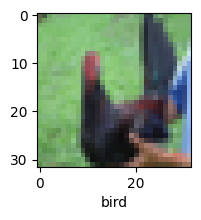

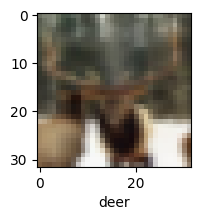

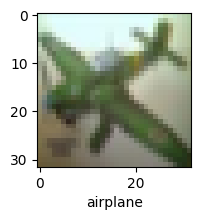

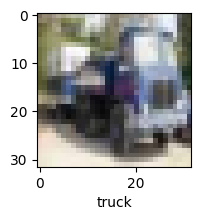

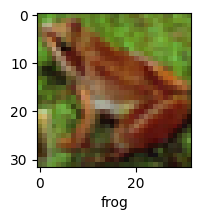

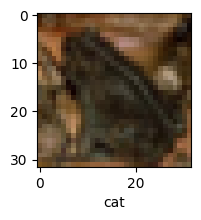

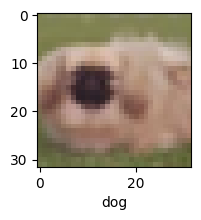

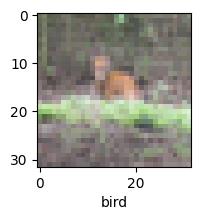

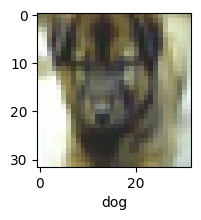

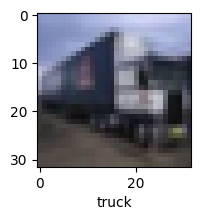

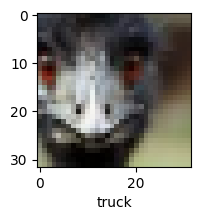

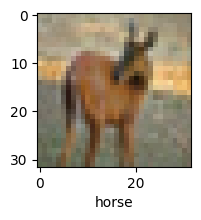

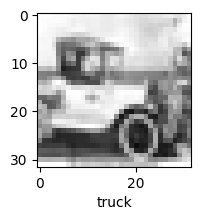

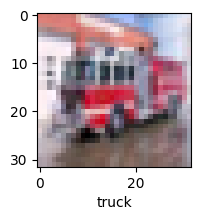

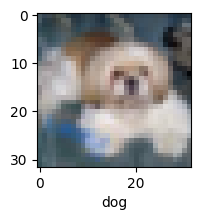

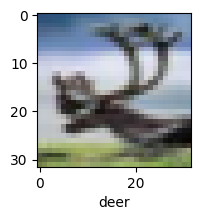

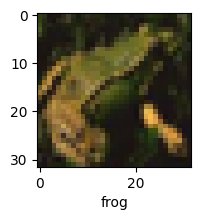

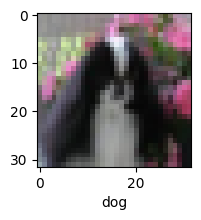

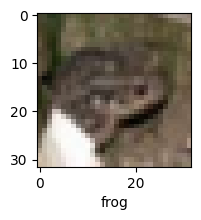

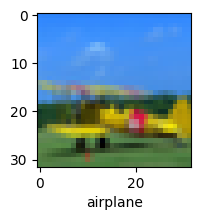

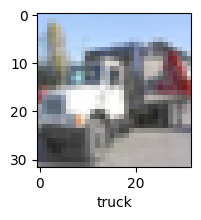

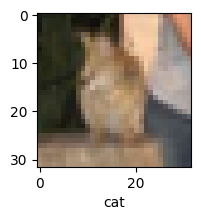

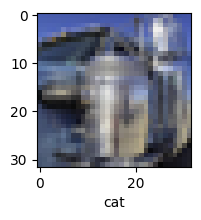

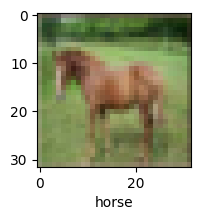

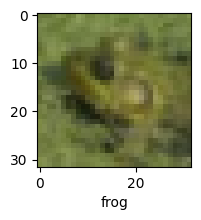

In [90]:
for i in range(25,50):
  plot(x_test,y_class,i)


In [92]:
from sklearn.metrics import classification_report

In [96]:
y_test_flat = y_test.ravel()

In [97]:
print(classification_report(y_test,y_class))

              precision    recall  f1-score   support

           0       0.73      0.73      0.73      1000
           1       0.93      0.69      0.80      1000
           2       0.68      0.52      0.59      1000
           3       0.49      0.53      0.51      1000
           4       0.66      0.64      0.65      1000
           5       0.50      0.72      0.59      1000
           6       0.78      0.76      0.77      1000
           7       0.79      0.68      0.73      1000
           8       0.79      0.82      0.80      1000
           9       0.73      0.83      0.78      1000

    accuracy                           0.69     10000
   macro avg       0.71      0.69      0.69     10000
weighted avg       0.71      0.69      0.69     10000



In [95]:
y_test.shape,y_class.shape

((10000, 1), (10000,))

In [98]:
from sklearn.metrics import confusion_matrix

In [100]:
cm = confusion_matrix(y_test,y_class)

In [102]:
import seaborn as sns

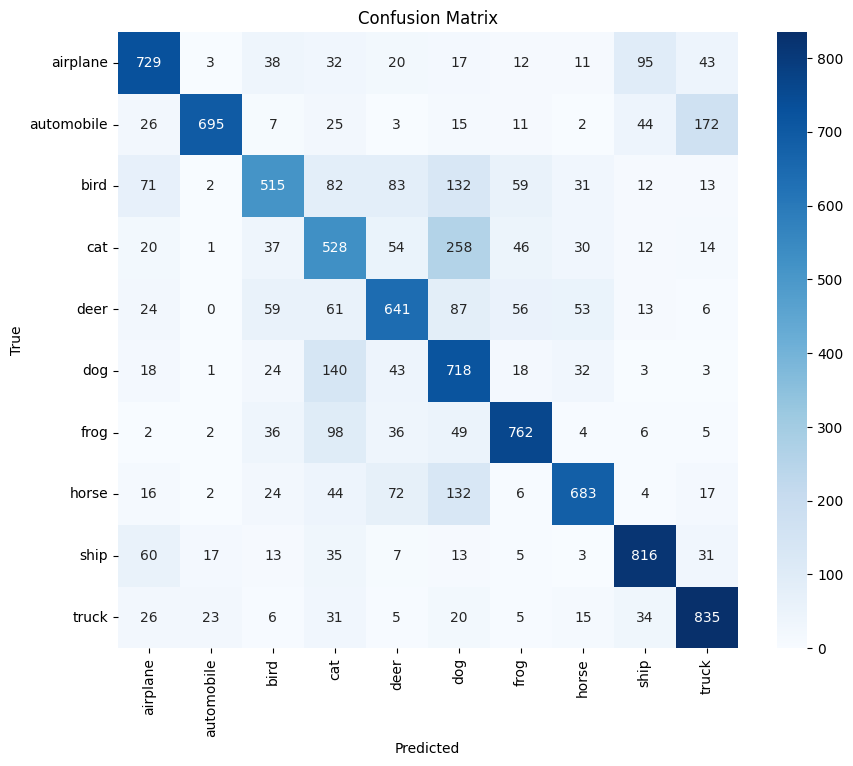

In [103]:
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
